# E123: what do the decomposition's readings say about the case-label pair?

**The answer.** The decomposition's readings put the case-label fine-tune and its memorising twin in the same place.
The route split, and the copies made inside the decomposition, read all four fine-tunes as carried by subcomponents
the masks keep off. No trigger task had landed there before. The independent definition reads both arms "not through
the capability", so the two sides agree on the real arm, but neither separates the pair. Removing the switched-on
subcomponents hurts the twin more than chance, the opposite of a reuse reading. No task is yet read as reuse by both.

*regating-lead, 2026-11-06. Report `reports/analyses/2026-11-06_analysis_e123-case-label-both-readings.md`; plan
`reports/plans/2026-11-06_plan_e123-case-label-both-readings.md`. Provisional: no independent check.*


## What we were trying to test

The project asks whether the decomposition's account of a fine-tune agrees with an independent account of whether the
fine-tune reuses something the model already had. E112 built one pair of fine-tunes of the 67M model to that
independent definition's shape, and this run reads the same four saved fine-tunes from the decomposition's side.

**The pair.** In the real arm the model learns to answer " carpet" after a trigger when the word before it is
capitalised, and " camel" when it is not. In the twin each word form gets its label from a seeded shuffle, so only
memory can learn it. Each arm has two seeds. The twin trained ten times longer and its update is about three times the
real arm's, a confound carried through every comparison.

**The definition's side, already read.** Under the adopted definition, a fine-tune reuses a capability if its answer
is a small function of a readout the original model already has and carries to held-out words. It must also break
when that readout is removed or patched. The real arm passes the first two tests on the case readout. Its label barely moves
when the readout is removed or patched, so E112 and E113 read it "not through C". The twin reads "not through C" too.
Nothing here changes those verdicts.

**The decomposition's side, read here**, on 256 windows of train-pair words the fine-tune never saw, at the trigger:

- *The route split.* The gain in the log-odds of the window's own label is split into shares. The re-switching share
  $r$ is the part gained when Γ switches on released subcomponents it kept off before; 1 means all of it. The
  masked-off share is the part carried by subcomponents Γ still keeps off. A state reads "re-switching" when $r$ is at
  least 0.6 with little masked-off share, "masked-off" when that share is at least 0.5 with $r$ at most 0.35, and
  "neither" otherwise. Re-switching is the decomposition's reuse-like reading.
- *Teacher training.* The decomposition's subcomponents are trained to copy each fine-tuned model, with Γ frozen. The
  copy is read by the route split, to check the reading survives when the change is written in the decomposition's
  own terms.
- *The removal test.* The switched-on set is the subcomponents whose mask at the trigger rises by more than 0.3 after
  fine-tuning. Removing it takes some share of the gain; we subtract the share it takes from the original model and
  compare with 20 random sets of the same size. "Through", the reuse-like reading, needs at least 0.10 and more than
  every random set.


## What we expected, and why

- **Route split: "neither" on all four**, with $r$ near one half. Every earlier trigger task's fine-tunes read $r$
  between 0.49 and 0.61, and the share followed the task more than the update. Real and twin close together.
- **Copies: the same label as their fine-tune**, within 0.06 in $r$, as all six of E119's task-window copies were.
- **Removal: "not" on both arms**, since nothing suggested the switched-on set would carry this kind of label.
- **Jointly**, no reuse label from the route split or the copies, and both sides saying "not" from the removal.

Every control in the first stage passed. The original model's accuracy and each fine-tune's gain matched E112's and
E114's numbers, the two forward paths agreed exactly, and the rules read their positive controls as filed.


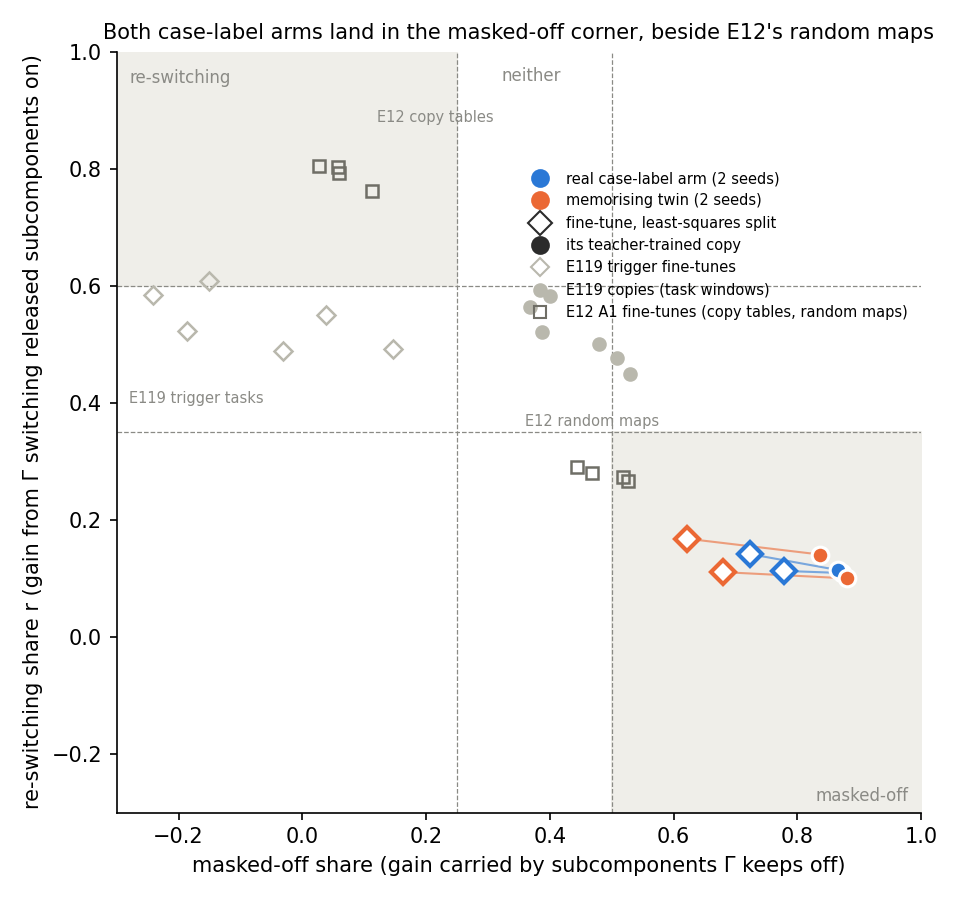

In [1]:
from IPython.display import Image

Image("../experiments/case_label_both/figures/route.png", width=640)


## Where does each fine-tune carry its gain, and where do the copies land?

**Reading it.** Every case-label fine-tune lands in the masked-off corner, real and twin alike. The open diamonds are
the four fine-tunes: their re-switching share is 0.11 to 0.17 and their masked-off share 0.62 to 0.78. Earlier trigger
tasks, the grey diamonds, sat near one half on the vertical axis and near zero on the horizontal. The only earlier
fine-tunes in this corner are two of E12's random maps, which were built to need a new map. The filled circles are the
copies inside the decomposition: each keeps the behaviour and moves a little further into the corner, to a masked-off
share of 0.84 to 0.88. The two arms sit within 0.06 of each other, so neither reading separates them. One caveat: the
copies keep most of the log-odds gain but only about seven tenths of the margin between the two labels.


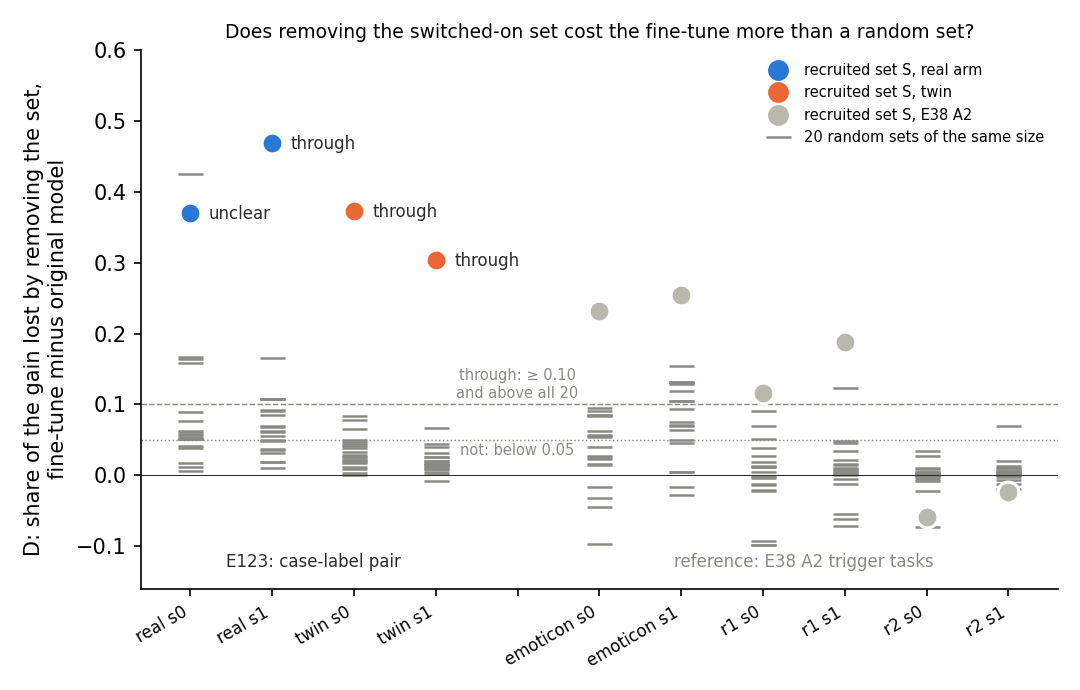

In [2]:
Image("../experiments/case_label_both/figures/removal.png", width=720)


## Does removing the switched-on set cost the fine-tune more than chance?

**Reading it.** For the twin, clearly yes; for the real arm, on one seed of two. Removing the twin's switched-on set
costs 0.37 and 0.30 more of its gain than the same removal costs the original model. Its random sets reach 0.08 at
most. Real seed 1 reads 0.47 against a random best of 0.16. Real seed 0 reads 0.37, but one random set reached 0.43,
so it reads "unclear". All four sit above the earlier trigger tasks' reference, in grey on the right. The twin's update
is three times larger, so its bigger switched-on set doing more of the work may be size, not kind.


## The three readings beside the definition

Each arm's label is its two seeds' common label, else "seeds disagree". The joint outcome is the filed name for how
the real arm's reading sits beside the twin's. "Real new-like" means the real arm reads new-like and the twin does not
read reuse-like; "reversed" means the twin reads reuse-like and the real arm does not. None of these is the
definition's verdict, which stays E112's for both arms.


In [3]:
import json
from pathlib import Path

from IPython.display import Markdown

score = json.loads(Path("../experiments/case_label_both/results/case_label_both.json").read_text())["score"]
names = {"route_fine_tune": "route split, fine-tunes", "copy": "route split, copies", "removal": "removal of the switched-on set"}
rows = ["| reading | real arm | twin | joint outcome | definition, both arms |", "|---|---|---|---|---|"]
for k, name in names.items():
    s = score[k]
    rows.append(f"| {name} | {s['arms']['real']} | {s['arms']['twin']} | {s['joint']} | not through C |")
Markdown("\n".join(rows))


| reading | real arm | twin | joint outcome | definition, both arms |
|---|---|---|---|---|
| route split, fine-tunes | masked-off | masked-off | real new-like | not through C |
| route split, copies | masked-off | masked-off | real new-like | not through C |
| removal of the switched-on set | seeds disagree | through | reversed | not through C |

## What we learned

On the one small-model pair the definition can read, the route split and the definition agree that the real
fine-tune does not run through existing structure. That agreement has no teeth, because both sides give the memorising
twin the same answer. The two labels are also about different things: the case readout on one side, which
subcomponents Γ switches on on the other. The removal test points the other way, finding the twin's switched-on set
carrying its gain, which the plan said should not be called a reuse reading. So no task is yet read as reuse by both
sides. The masked-off corner is new for a trigger task; a learnt and a memorised fine-tune both reach it, so it belongs
to this task rather than to how the update was learnt.

## How compelling is the evidence

Two seeds per arm on one task, one trigger and 256 windows; the read-window gains sit within half a nat of the
1,024-window ones. The seed spread in the route shares is at most 0.06, far from any label line. The removal's null is
20 random sets per state, and on real seed 0 one random set alone decides the class. The twin's larger update does not
touch the readings that agree across arms, but it does touch the removal's arm difference. The route split reads one
position and says how Γ routes the gain, not whether the parts are new: a new circuit built from old pieces reads as
elicited to the decomposition.

## Surprises

- **The route split's lean reversed in kind.** We expected "neither" with $r$ near one half; all four fine-tunes read
  "masked-off" with $r$ near 0.13. Why is not worked out. One untested candidate: both labels start from a log-odds
  near −14.5 at the trigger, so most of the gain may sit on subcomponents Γ never switches on there.
- **The removal's lean reversed on the twin.** We expected "not" on both arms; the twin reads "through" on both seeds.
- Smaller misses: the copies kept about seven tenths of the label margin against a filed nine tenths, and one copy's
  gain ratio is 0.896 against 0.90.

## What next

- Read E124's pronoun states or E125's repeat-label pair by both sides. If the definition reads "reuses C" and the
  route split reads re-switching there, the agreement has teeth; if the route split reads masked-off there too, the
  corner belongs to label tasks, not to reuse.
- A twin stopped at the real arm's update size would say whether the removal's arm difference is size. That is a new
  fine-tune and a plan of its own.


## Scorecard

| id | claim in words | rule | read | verdict |
|---|---|---|---|---|
| R1 | fine-tunes read "neither", r 0.45-0.65, arms within 0.15 | E12's lines | masked-off ×4, r 0.11-0.17, arms within 0.06 | lean missed; arm closeness held |
| R2 | copies keep behaviour, r within 0.06, "neither" | fit accuracy ≥ 0.90, then route label | accuracy ≥ 0.97, r within 0.03, masked-off ×4 | label missed |
| R3 | switched-on set nonempty, "not" on both arms | E38 A2's seed rule | 196-281 subcomponents; real seeds disagree, twin through | class missed |
| joint | route "no label", copy "no label", removal "real new-like" | filed joint table | real new-like, real new-like, reversed | missed |
| stage 0 | 33 controls | stop rules | 33 pass | pass |

## Not run

- Copies on Pile rows; a second copy seed. The removal on held-out windows, at every position, or against a null set.
- The route split on held-out-pair windows, where the twin is at chance.
- A size-matched twin; any fresh pair. Anything on the definition side. No independent check.

*Provenance: MATS debug L40, job 54711, about 8.5 minutes, $0. Results
`experiments/case_label_both/results/case_label_both.json`, log `results/large/run.log`.*
